In [1]:

SID4  = 2733
SEED  = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4}  SEED={SEED}  SLICE={SLICE}  HP_ID={HP_ID}  CLS_A={CLS_A}  CLS_B={CLS_B}")

SID4=2733  SEED=2733  SLICE=733  HP_ID=3  CLS_A=3  CLS_B=7


In [3]:
!pip install -q gdown

In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  

import random, logging, sys, time, json
import numpy as np
import torch

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(message)s",
    handlers=[logging.FileHandler("/kaggle/working/RUN_LOG_part2.txt", mode="w"),
              logging.StreamHandler(sys.stdout)],
    force=True,
)
logging.getLogger("httpx").setLevel(logging.WARNING)
log = logging.getLogger("hw12_p2")

import transformers, datasets
log.info(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
log.info(f"GPU: {torch.cuda.get_device_name(0)} | visible: {torch.cuda.device_count()}")
log.info(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")

2026-11-19 22:54:15,367 | NumExpr defaulting to 4 threads.
2026-11-19 22:54:15,955 | TensorFlow version 2.21.0 available.
2026-11-19 22:54:15,960 | JAX version 0.11.1 available.
2026-11-19 22:54:17,448 | SID4=2733 SEED=2733 SLICE=733 HP_ID=3 CLS_A=3 CLS_B=7
2026-11-19 22:54:17,665 | GPU: Tesla T4 | visible: 1
2026-11-19 22:54:17,666 | torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5


In [8]:
TEACHER_ROOT = "/kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model"
!find /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model -maxdepth 3 -exec ls -ld {} \; | head -40

drwxrwxrwx 1 root root 0 Nov 19 23:12 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model
-rw-rw-rw- 1 root root 944 Nov 19 23:10 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model/config.json
-rw-rw-rw- 1 root root 437964800 Nov 19 23:11 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model/model.safetensors
-rw-rw-rw- 1 root root 695 Nov 19 23:10 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model/special_tokens_map.json
-rw-rw-rw- 1 root root 711649 Nov 19 23:10 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model/tokenizer.json
-rw-rw-rw- 1 root root 1381 Nov 19 23:10 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model/tokenizer_config.json
-rw-rw-rw- 1 root root 231508 Nov 19 23:10 /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model/vocab.txt


In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

TEACHER_DIR = "/kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model"
DEVICE = "cuda"

t_tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()

log.info(f"Teacher loaded locally from {TEACHER_DIR}")
log.info(f"Arch: {teacher.config.architectures} | model_type: {teacher.config.model_type}")
log.info(f"num_labels: {teacher.config.num_labels} | id2label: {teacher.config.id2label}")
log.info(f"Params: {sum(p.numel() for p in teacher.parameters())/1e6:.1f}M")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

2026-11-19 23:16:19,863 | Teacher loaded locally from /kaggle/input/datasets/sadaffatimasyeda/hw12-teacher-model/teacher_model
2026-11-19 23:16:19,865 | Arch: ['BertForSequenceClassification'] | model_type: bert
2026-11-19 23:16:19,865 | num_labels: 4 | id2label: {0: 'WORLD', 1: 'SPORTS', 2: 'BUSINESS', 3: 'SCI/TECH'}
2026-11-19 23:16:19,867 | Params: 109.5M


In [10]:
from datasets import load_dataset

ag = load_dataset("fancyzhx/ag_news")
train_ds, test_ds = ag["train"], ag["test"]
LABELS = ["World", "Sports", "Business", "Sci/Tech"]

log.info(f"AG News loaded: train={len(train_ds)} test={len(test_ds)}")
log.info(f"Dataset label names: {train_ds.features['label'].names}")
log.info(f"Example: label={train_ds[SLICE]['label']} | {train_ds[SLICE]['text'][:120]}")

2026-11-19 23:17:38,432 | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

2026-11-19 23:17:41,479 | AG News loaded: train=120000 test=7600
2026-11-19 23:17:41,480 | Dataset label names: ['World', 'Sports', 'Business', 'Sci/Tech']
2026-11-19 23:17:41,483 | Example: label=0 | Israel Turns Up Heat on Palestinian Hunger Strike (Reuters) Reuters - Israel declared psychological war on\hunger-striki


In [11]:
from tqdm.auto import tqdm

MAX_LEN = 128
BS_INFER = 256

@torch.no_grad()
def get_logits(model, tok, texts, bs=BS_INFER):
    model.eval()
    out = []
    for i in tqdm(range(0, len(texts), bs), desc="logits"):
        enc = tok(texts[i:i+bs], truncation=True, max_length=MAX_LEN,
                  padding=True, return_tensors="pt").to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(**enc).logits.float().cpu())
    return torch.cat(out)

train_texts  = train_ds["text"]
train_labels = torch.tensor(train_ds["label"])

t0 = time.perf_counter()
teacher_train_logits = get_logits(teacher, t_tok, train_texts)
log.info(f"Teacher logits: shape={tuple(teacher_train_logits.shape)} in {time.perf_counter()-t0:.1f}s")

train_acc = (teacher_train_logits.argmax(-1) == train_labels).float().mean().item()
log.info(f"Teacher accuracy on train (sanity check): {train_acc:.4f}")

torch.save(teacher_train_logits, "/kaggle/working/teacher_train_logits.pt")
log.info("Saved teacher_train_logits.pt")

logits:   0%|          | 0/469 [00:00<?, ?it/s]

2026-11-19 23:22:17,557 | Teacher logits: shape=(120000, 4) in 218.1s
2026-11-19 23:22:17,596 | Teacher accuracy on train (sanity check): 0.9895
2026-11-19 23:22:17,629 | Saved teacher_train_logits.pt


In [12]:
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding, get_linear_schedule_with_warmup

STUDENT_ID = "distilbert/distilbert-base-uncased"
s_tok = AutoTokenizer.from_pretrained(STUDENT_ID)

# ---- Fixed training settings (identical for every run) ----
EPOCHS, BS_TRAIN, LR, WARMUP_FRAC, WD = 1, 64, 5e-5, 0.06, 0.01
VAL_SIZE = 5000   # held out from train to pick best T / alpha (test set stays untouched for selection)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(train_ds), generator=g)
val_idx, tr_idx = perm[:VAL_SIZE].tolist(), perm[VAL_SIZE:].tolist()

def tok_fn(b):
    return s_tok(b["text"], truncation=True, max_length=MAX_LEN)

train_tok = (train_ds.add_column("t_logits", teacher_train_logits.tolist())
                     .map(tok_fn, batched=True, remove_columns=["text"]))
tr_set   = train_tok.select(tr_idx)
val_set  = train_tok.select(val_idx).remove_columns(["t_logits"])
test_set = test_ds.map(tok_fn, batched=True, remove_columns=["text"])
collate  = DataCollatorWithPadding(s_tok)
log.info(f"Student data: train={len(tr_set)} val={len(val_set)} test={len(test_set)}")
log.info(f"Fixed settings: epochs={EPOCHS} bs={BS_TRAIN} lr={LR} warmup={WARMUP_FRAC} wd={WD} max_len={MAX_LEN} fp16")

# ---- Distillation loss: loss = alpha*CE + (1-alpha)*KL ----
def kd_loss(s_logits, t_logits, labels, T, alpha):
    ce = F.cross_entropy(s_logits, labels)                        # student vs true labels
    kl = F.kl_div(F.log_softmax(s_logits / T, dim=-1),            # student vs teacher (softened by T)
                  F.softmax(t_logits / T, dim=-1),
                  reduction="batchmean") * (T * T)                # T^2 keeps gradient scale comparable (Hinton et al.)
    return alpha * ce + (1 - alpha) * kl, ce, kl

@torch.no_grad()
def evaluate(model, ds, bs=256):
    model.eval(); preds = []
    for b in DataLoader(ds, batch_size=bs, collate_fn=collate):
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE))
        preds.append(out.logits.argmax(-1).cpu())
    preds = torch.cat(preds)
    acc = (preds == torch.tensor(ds["label"])).float().mean().item()
    return acc, preds

def train_student(T, alpha, tag):
    # fresh student from the same pretrained checkpoint, same SEED every run
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_ID, num_labels=4,
        id2label={i: l for i, l in enumerate(LABELS)}, label2id={l: i for i, l in enumerate(LABELS)},
    ).to(DEVICE)
    dl = DataLoader(tr_set, batch_size=BS_TRAIN, shuffle=True, collate_fn=collate,
                    generator=torch.Generator().manual_seed(SEED))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    total = EPOCHS * len(dl)
    sch = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda")

    hist, step, t0 = [], 0, time.perf_counter()
    model.train()
    for ep in range(EPOCHS):
        for b in tqdm(dl, desc=tag, mininterval=15):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                s_logits = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"]).logits
            loss, ce, kl = kd_loss(s_logits.float(), b["t_logits"].float(), b["labels"], T, alpha)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            step += 1
            if step == 1 or step % 100 == 0:
                hist.append(dict(step=step, loss=loss.item(), ce=ce.item(), kl=kl.item()))
            if step == 1 or step % 500 == 0 or step == total:
                log.info(f"[{tag}] step {step}/{total} loss={loss.item():.4f} ce={ce.item():.4f} "
                         f"kl={kl.item():.4f} lr={sch.get_last_lr()[0]:.2e}")
    train_time = time.perf_counter() - t0

    val_acc, _ = evaluate(model, val_set)
    test_acc, test_preds = evaluate(model, test_set)
    log.info(f"[{tag}] DONE T={T} alpha={alpha} | val_acc={val_acc:.4f} test_acc={test_acc:.4f} | train_time={train_time:.0f}s")
    return model, dict(tag=tag, T=T, alpha=alpha, val_acc=val_acc, test_acc=test_acc,
                       train_time_s=train_time, history=hist), test_preds

log.info("KD loss + training function defined.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

2026-11-19 23:24:52,155 | Student data: train=115000 val=5000 test=7600
2026-11-19 23:24:52,157 | Fixed settings: epochs=1 bs=64 lr=5e-05 warmup=0.06 wd=0.01 max_len=128 fp16
2026-11-19 23:24:52,159 | KD loss + training function defined.


In [13]:
import gc, pandas as pd

sweep_T = []
for T in [1, 2, 5, 10]:
    model, res, _ = train_student(T=T, alpha=0.5, tag=f"T{T}_a0.5")
    sweep_T.append(res)
    del model; gc.collect(); torch.cuda.empty_cache()
    with open("/kaggle/working/sweep_T.json", "w") as f:      # saved after every run, in case the session dies
        json.dump(sweep_T, f, indent=2)

best_T_run = max(sweep_T, key=lambda r: r["val_acc"])          # chosen on validation, not test
BEST_T = best_T_run["T"]

tbl_T = pd.DataFrame([{"T": r["T"], "alpha": r["alpha"], "val_acc": round(r["val_acc"], 4),
                       "test_acc": round(r["test_acc"], 4), "train_time_s": round(r["train_time_s"])}
                      for r in sweep_T])
print(tbl_T.to_string(index=False))
log.info(f"Temperature sweep done. BEST_T={BEST_T} (val_acc={best_T_run['val_acc']:.4f})")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


T1_a0.5:   0%|          | 0/1797 [00:00<?, ?it/s]

2026-11-19 23:25:33,275 | [T1_a0.5] step 1/1797 loss=1.3625 ce=1.3756 kl=1.3494 lr=4.67e-07
2026-11-19 23:26:59,378 | [T1_a0.5] step 500/1797 loss=0.1633 ce=0.1709 kl=0.1557 lr=3.84e-05
2026-11-19 23:28:24,938 | [T1_a0.5] step 1000/1797 loss=0.1895 ce=0.1932 kl=0.1857 lr=2.36e-05
2026-11-19 23:29:50,727 | [T1_a0.5] step 1500/1797 loss=0.0608 ce=0.0658 kl=0.0559 lr=8.79e-06
2026-11-19 23:30:41,687 | [T1_a0.5] step 1797/1797 loss=0.1578 ce=0.2057 kl=0.1099 lr=0.00e+00
2026-11-19 23:30:56,674 | [T1_a0.5] DONE T=1 alpha=0.5 | val_acc=0.9418 test_acc=0.9433 | train_time=310s


... (8 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


T10_a0.5:   0%|          | 0/1797 [00:00<?, ?it/s]

2026-11-19 23:41:44,915 | [T10_a0.5] step 1/1797 loss=5.4269 ce=1.3756 kl=9.4782 lr=4.67e-07
2026-11-19 23:43:10,942 | [T10_a0.5] step 500/1797 loss=0.3694 ce=0.1767 kl=0.5621 lr=3.84e-05
2026-11-19 23:44:36,823 | [T10_a0.5] step 1000/1797 loss=0.7175 ce=0.3717 kl=1.0634 lr=2.36e-05
2026-11-19 23:46:02,354 | [T10_a0.5] step 1500/1797 loss=0.1183 ce=0.0275 kl=0.2091 lr=8.79e-06
2026-11-19 23:46:53,284 | [T10_a0.5] step 1797/1797 loss=0.3754 ce=0.2878 kl=0.4629 lr=0.00e+00
2026-11-19 23:47:08,317 | [T10_a0.5] DONE T=10 alpha=0.5 | val_acc=0.9416 test_acc=0.9418 | train_time=309s
 T  alpha  val_acc  test_acc  train_time_s
 1    0.5   0.9418    0.9433           310
 2    0.5   0.9384    0.9433           308
 5    0.5   0.9406    0.9432           308
10    0.5   0.9416    0.9418           309
2026-11-19 23:47:08,773 | Temperature sweep done. BEST_T=1 (val_acc=0.9418)


In [15]:
sweep_A = []
best_run, best_preds = None, None
BEST_DIR = "/kaggle/working/best_student"

for a in [0.25, 0.5, 0.75]:
    model, res, preds = train_student(T=BEST_T, alpha=a, tag=f"T{BEST_T}_a{a}")
    sweep_A.append(res)
    if best_run is None or res["val_acc"] > best_run["val_acc"]:      # pick on validation
        best_run, best_preds = res, preds
        model.save_pretrained(BEST_DIR); s_tok.save_pretrained(BEST_DIR)
        log.info(f"New best student saved: {res['tag']} (val_acc={res['val_acc']:.4f})")
    del model; gc.collect(); torch.cuda.empty_cache()
    with open("/kaggle/working/sweep_alpha.json", "w") as f:
        json.dump(sweep_A, f, indent=2)

tbl_A = pd.DataFrame([{"T": r["T"], "alpha": r["alpha"], "val_acc": round(r["val_acc"], 4),
                       "test_acc": round(r["test_acc"], 4), "train_time_s": round(r["train_time_s"])}
                      for r in sweep_A])
print(tbl_A.to_string(index=False))
log.info(f"Alpha sweep done. BEST student = {best_run['tag']} | val={best_run['val_acc']:.4f} test={best_run['test_acc']:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


T1_a0.25:   0%|          | 0/1797 [00:00<?, ?it/s]

2026-11-19 23:51:36,192 | [T1_a0.25] step 1/1797 loss=1.3560 ce=1.3756 kl=1.3494 lr=4.67e-07
2026-11-19 23:53:02,599 | [T1_a0.25] step 500/1797 loss=0.1598 ce=0.1712 kl=0.1560 lr=3.84e-05
2026-11-19 23:54:28,177 | [T1_a0.25] step 1000/1797 loss=0.2049 ce=0.2119 kl=0.2025 lr=2.36e-05
2026-11-19 23:55:54,066 | [T1_a0.25] step 1500/1797 loss=0.0546 ce=0.0627 kl=0.0519 lr=8.79e-06
2026-11-19 23:56:44,734 | [T1_a0.25] step 1797/1797 loss=0.1141 ce=0.1846 kl=0.0906 lr=0.00e+00
2026-11-19 23:56:59,614 | [T1_a0.25] DONE T=1 alpha=0.25 | val_acc=0.9406 test_acc=0.9430 | train_time=309s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-11-19 23:56:59,978 | New best student saved: T1_a0.25 (val_acc=0.9406)


... (6 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


T1_a0.75:   0%|          | 0/1797 [00:00<?, ?it/s]

2026-11-20 00:02:25,412 | [T1_a0.75] step 1/1797 loss=1.3691 ce=1.3756 kl=1.3494 lr=4.67e-07
2026-11-20 00:03:51,743 | [T1_a0.75] step 500/1797 loss=0.1943 ce=0.1980 kl=0.1831 lr=3.84e-05
2026-11-20 00:05:17,269 | [T1_a0.75] step 1000/1797 loss=0.1875 ce=0.1901 kl=0.1796 lr=2.36e-05
2026-11-20 00:06:42,715 | [T1_a0.75] step 1500/1797 loss=0.0578 ce=0.0600 kl=0.0512 lr=8.79e-06
2026-11-20 00:07:33,516 | [T1_a0.75] step 1797/1797 loss=0.1738 ce=0.1972 kl=0.1036 lr=0.00e+00
2026-11-20 00:07:49,237 | [T1_a0.75] DONE T=1 alpha=0.75 | val_acc=0.9408 test_acc=0.9420 | train_time=308s
 T  alpha  val_acc  test_acc  train_time_s
 1   0.25   0.9406    0.9430           309
 1   0.50   0.9418    0.9433           308
 1   0.75   0.9408    0.9420           308
2026-11-20 00:07:49,659 | Alpha sweep done. BEST student = T1_a0.5 | val=0.9418 test=0.9433


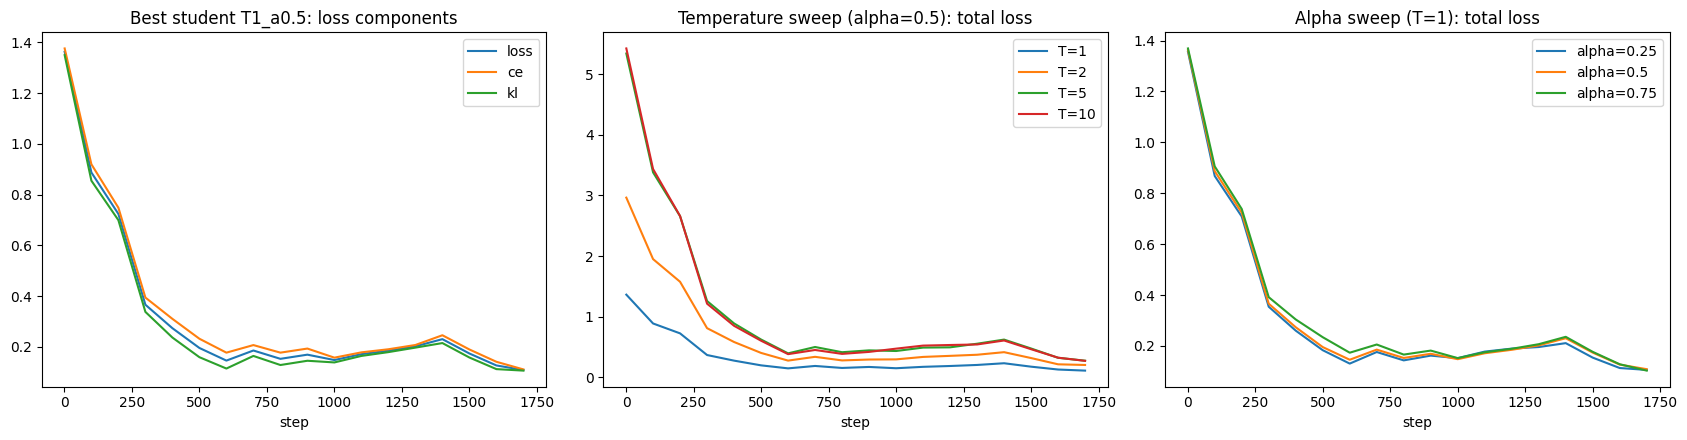

     tag  T  alpha  val_acc  test_acc  train_time_s
 T1_a0.5  1   0.50   0.9418    0.9433      309.5005
 T2_a0.5  2   0.50   0.9384    0.9433      308.0742
 T5_a0.5  5   0.50   0.9406    0.9432      308.2043
T10_a0.5 10   0.50   0.9416    0.9418      308.5263
T1_a0.25  1   0.25   0.9406    0.9430      308.7351
 T1_a0.5  1   0.50   0.9418    0.9433      307.8794
T1_a0.75  1   0.75   0.9408    0.9420      308.2568
2026-11-20 00:19:22,832 | Saved figures/loss_trends.png


In [17]:
import matplotlib.pyplot as plt
os.makedirs("/kaggle/working/figures", exist_ok=True)

all_runs = sweep_T + sweep_A
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) best run: total / CE / KL
h = pd.DataFrame(best_run["history"])
for col in ["loss", "ce", "kl"]:
    axes[0].plot(h["step"], h[col].rolling(3, min_periods=1).mean(), label=col)
axes[0].set_title(f"Best student {best_run['tag']}: loss components"); axes[0].set_xlabel("step"); axes[0].legend()

# (b) temperature sweep: total loss
for r in sweep_T:
    h = pd.DataFrame(r["history"])
    axes[1].plot(h["step"], h["loss"].rolling(3, min_periods=1).mean(), label=f"T={r['T']}")
axes[1].set_title("Temperature sweep (alpha=0.5): total loss"); axes[1].set_xlabel("step"); axes[1].legend()

# (c) alpha sweep: total loss
for r in sweep_A:
    h = pd.DataFrame(r["history"])
    axes[2].plot(h["step"], h["loss"].rolling(3, min_periods=1).mean(), label=f"alpha={r['alpha']}")
axes[2].set_title(f"Alpha sweep (T={BEST_T}): total loss"); axes[2].set_xlabel("step"); axes[2].legend()

plt.tight_layout(); plt.savefig("/kaggle/working/figures/loss_trends.png", dpi=120); plt.show()

summary = pd.DataFrame([{k: (round(v, 4) if isinstance(v, float) else v)
                         for k, v in r.items() if k != "history"} for r in all_runs])
print(summary.to_string(index=False))
log.info("Saved figures/loss_trends.png")

In [16]:
from pathlib import Path
def dir_size_mb(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 1024**2


del teacher; gc.collect(); torch.cuda.empty_cache()

test_texts  = test_ds["text"]
test_labels = torch.tensor(test_ds["label"])

def measure_classifier(name, model_dir, tok, n_lat=300, warm=20):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    m = AutoModelForSequenceClassification.from_pretrained(model_dir).to(DEVICE).eval()


    torch.cuda.synchronize(); t0 = time.perf_counter()
    logits = get_logits(m, tok, test_texts, bs=64)
    torch.cuda.synchronize(); full_s = time.perf_counter() - t0
    preds = logits.argmax(-1)
    acc = (preds == test_labels).float().mean().item()


    lat = []
    with torch.no_grad():
        for i in range(warm + n_lat):
            enc = tok(test_texts[SLICE + i], truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
            torch.cuda.synchronize(); t0 = time.perf_counter()
            with torch.autocast("cuda", dtype=torch.float16):
                m(**enc)
            torch.cuda.synchronize()
            if i >= warm: lat.append((time.perf_counter() - t0) * 1000)
    p50, p95 = np.percentile(lat, [50, 95])
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    params  = sum(p.numel() for p in m.parameters()) / 1e6
    disk    = dir_size_mb(model_dir)
    del m; gc.collect(); torch.cuda.empty_cache()

    r = dict(model=name, acc=acc, p50_ms=p50, p95_ms=p95, peak_gb=peak_gb,
             disk_mb=disk, params_M=params, full_test_s=full_s)
    log.info(f"{name}: acc={acc:.4f} p50={p50:.2f}ms p95={p95:.2f}ms peak={peak_gb:.3f}GB "
             f"disk={disk:.1f}MB params={params:.1f}M full_test={full_s:.1f}s")
    return r, preds

t_res, t_preds = measure_classifier("Teacher (BERT-base)", TEACHER_DIR, t_tok)
s_res, s_preds = measure_classifier(f"Best distilled student ({best_run['tag']})", BEST_DIR, s_tok)

tbl2 = pd.DataFrame([{
    "Configuration": r["model"], "Accuracy": f"{r['acc']:.4f}",
    "p50 / p95 latency (ms)": f"{r['p50_ms']:.2f} / {r['p95_ms']:.2f}",
    "Peak memory (GB)": f"{r['peak_gb']:.3f}", "Size on disk (MB)": f"{r['disk_mb']:.1f}"}
    for r in [t_res, s_res]])
print("Table HW11.2 - distillation comparison on AG News (test set, same T4)")
print(tbl2.to_string(index=False))

with open("/kaggle/working/results_part2.json", "w") as f:
    json.dump(dict(sweep_T=[{k: v for k, v in r.items() if k != "history"} for r in sweep_T],
                   sweep_alpha=[{k: v for k, v in r.items() if k != "history"} for r in sweep_A],
                   best=best_run["tag"], teacher=t_res, student=s_res), f, indent=2)
log.info("Saved results_part2.json")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

logits:   0%|          | 0/119 [00:00<?, ?it/s]

2026-11-20 00:17:30,730 | Teacher (BERT-base): acc=0.9443 p50=13.57ms p95=15.05ms peak=0.779GB disk=418.6MB params=109.5M full_test=12.2s


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

logits:   0%|          | 0/119 [00:00<?, ?it/s]

2026-11-20 00:17:40,638 | Best distilled student (T1_a0.5): acc=0.9434 p50=6.72ms p95=7.17ms peak=0.514GB disk=256.1MB params=67.0M full_test=6.7s
Table HW11.2 - distillation comparison on AG News (test set, same T4)
                   Configuration Accuracy p50 / p95 latency (ms) Peak memory (GB) Size on disk (MB)
             Teacher (BERT-base)   0.9443          13.57 / 15.05            0.779             418.6
Best distilled student (T1_a0.5)   0.9434            6.72 / 7.17            0.514             256.1
2026-11-20 00:17:40,644 | Saved results_part2.json


In [18]:
rows = []
for c, name in enumerate(LABELS):
    m = test_labels == c
    ta = (t_preds[m] == c).float().mean().item()
    sa = (s_preds[m] == c).float().mean().item()
    rows.append(dict(cls=name, n=int(m.sum()), teacher_acc=round(ta, 4),
                     student_acc=round(sa, 4), drop_pts=round((ta - sa) * 100, 2)))
per_class = pd.DataFrame(rows)
print("Per-class accuracy on AG News test")
print(per_class.to_string(index=False))

worst = per_class.loc[per_class["drop_pts"].idxmax(), "cls"]
wi = LABELS.index(worst)
log.info(f"Class that degrades most: {worst}")

mask = (test_labels == wi) & (t_preds == wi) & (s_preds != wi)
idx = mask.nonzero().flatten().tolist()
log.info(f"{worst}: {len(idx)} examples teacher-right / student-wrong")
print("Student's wrong predictions for these:", pd.Series([LABELS[s_preds[i]] for i in idx]).value_counts().to_dict())

pick = random.Random(SEED).sample(idx, min(5, len(idx)))
print(f"\nFive examples (true = {worst}, teacher correct, student wrong):")
for i in pick:
    print(f"\n[test #{i}] student said: {LABELS[s_preds[i]]}\n  {test_texts[i]}")

per_class.to_json("/kaggle/working/per_class_part2.json", orient="records", indent=2)

Per-class accuracy on AG News test
     cls    n  teacher_acc  student_acc  drop_pts
   World 1900       0.9489       0.9447      0.42
  Sports 1900       0.9884       0.9884      0.00
Business 1900       0.9137       0.9053      0.84
Sci/Tech 1900       0.9263       0.9353     -0.89
2026-11-20 00:20:48,399 | Class that degrades most: Business
2026-11-20 00:20:48,410 | Business: 55 examples teacher-right / student-wrong
Student's wrong predictions for these: {'Sci/Tech': 45, 'World': 9, 'Sports': 1}

Five examples (true = Business, teacher correct, student wrong):

[test #6849] student said: Sci/Tech
  Two top Nokia executives resign HELSINKI: Nokia said the respected head of its networks unit had resigned and another top networks official left in the second major departure of top management in two weeks at the world #39;s largest mobile phone maker.

[test #449] student said: World
  Botswana miners 'face dismissal' Botswana's giant Debswana diamond mining firm says it will sack worke

In [19]:
import shutil
shutil.make_archive("/kaggle/working/best_student_T1_a0.5", "zip", BEST_DIR)
log.info("Zipped best student checkpoint")

!ls -la /kaggle/working /kaggle/working/figures
from IPython.display import FileLink, display
for f in ["RUN_LOG_part2.txt", "results_part2.json", "per_class_part2.json",
          "figures/loss_trends.png", "best_student_T1_a0.5.zip"]:
    display(FileLink(f))

2026-11-20 00:21:37,546 | Zipped best student checkpoint
/kaggle/working:
total 243352
drwxr-xr-x 5 root root      4096 Nov 20 00:21 .
drwxr-xr-x 5 root root      4096 Nov 19 22:50 ..
drwxr-xr-x 2 root root      4096 Nov 20 00:02 best_student
-rw-r--r-- 1 root root 247203778 Nov 20 00:21 best_student_T1_a0.5.zip
drwxr-xr-x 2 root root      4096 Nov 20 00:19 figures
-rw-r--r-- 1 root root       466 Nov 20 00:20 per_class_part2.json
-rw-r--r-- 1 root root      1963 Nov 20 00:17 results_part2.json
-rw-r--r-- 1 root root      6693 Nov 20 00:21 RUN_LOG_part2.txt
-rw-r--r-- 1 root root      8312 Nov 20 00:07 sweep_alpha.json
-rw-r--r-- 1 root root     11012 Nov 19 23:47 sweep_T.json
-rw-r--r-- 1 root root   1921668 Nov 19 23:22 teacher_train_logits.pt
drwxr-xr-x 2 root root      4096 Nov 19 22:51 .virtual_documents

/kaggle/working/figures:
total 116
drwxr-xr-x 2 root root   4096 Nov 20 00:19 .
drwxr-xr-x 5 root root   4096 Nov 20 00:21 ..
-rw-r--r-- 1 root root 109810 Nov 20 00:19 loss_tren

/kaggle/working/RUN_LOG_part2.txt

/kaggle/working/results_part2.json

/kaggle/working/per_class_part2.json

/kaggle/working/figures/loss_trends.png

/kaggle/working/best_student_T1_a0.5.zip